# Assignment 3 - Hierarchical clustering
Compare WT_AL and WT_RF using Ward clustering with Euclidean distance. Run the cells in order.

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from scipy.cluster.hierarchy import linkage, cut_tree, dendrogram
from sklearn.preprocessing import StandardScaler
from pathlib import Path

results = Path('results/assignment3/hierarchical')
results.mkdir(parents=True, exist_ok=True)

gene_counts = [10, 100, 1000, 5000, 10000]
k_values = [2, 3, 4, 5]
plot_k = 3  # Example cut for the dendrogram.

## Load data

In [2]:
df = pd.read_csv('Data/SRP064298/gene_data.tsv', sep='\t')
metadata = pd.read_csv('Data/SRP064298/metadata_SRP064298.tsv', sep='\t')
metadata = metadata.set_index('refinebio_accession_code')

# Match the metadata to the expression columns.
metadata = metadata.loc[df.columns[1:]]
# Keep only wild-type AL/RF samples, excluding KO samples.
wt_samples = metadata['refinebio_title'].str.startswith(('WT_AL_', 'WT_RF_'))
metadata = metadata.loc[wt_samples].copy()
metadata.index.name = 'sample_id'

# Extract AL or RF from titles such as WT_AL_ZT00_A_RNA.
groups = metadata['refinebio_title'].str.split('_').str[1].rename('group')
# Transpose to samples x genes, then keep the selected samples.
samples = df.drop(columns='Gene').T.loc[metadata.index]
samples.index.name = 'sample_id'

# Check sample alignment and missing or infinite expression values.
assert samples.index.equals(groups.index)
assert np.isfinite(samples.to_numpy()).all()

print('Samples:', len(samples))
print(groups.value_counts())
print('Distinct sample titles:', metadata['refinebio_title'].nunique())

Samples: 546
group
AL    367
RF    179
Name: count, dtype: int64
Distinct sample titles: 72


## Select variable genes
Use the supplied normalized values. Select by variance before scaling. Keep row numbers so repeated gene names remain separate.

In [3]:
gene_variance = samples.var(axis=0)
gene_order = gene_variance[gene_variance > 0].sort_values(
    ascending=False, kind='mergesort'
).index

gene_ranking = pd.DataFrame({
    'gene_symbol': df['Gene'],
    'input_row': df.index,
    'variance': gene_variance,
}).loc[gene_order]
gene_ranking.index.name = 'gene_row'

for n_genes in gene_counts:
    gene_ranking.iloc[:n_genes].to_csv(results / f'top_{n_genes}_genes.csv')

gene_ranking.head(10)

,gene_symbol,input_row,variance
gene_row,,,
9907,Lars2,9907,1604.011366
28075,Mir6236,28075,577.956662
26973,Mup15,26973,562.459708
26980,Mup17,26980,505.713260
7612,Grip2,7612,491.777940
19655,AA474408,19655,476.386073
27072,Gm26822,27072,443.752424
19759,Saa1,19759,421.673108
9096,Alas1,9096,387.049713


## Run hierarchical clustering
Build one tree per gene count, then cut it at each k.


In [7]:
trees = {}
cluster_labels = pd.DataFrame(index=samples.index)
summaries = []

for n_genes in gene_counts:
    selected_genes = gene_order[:n_genes]
    scaled_data = StandardScaler().fit_transform(samples.loc[:, selected_genes])
    trees[n_genes] = linkage(scaled_data, method='ward', metric='euclidean')
    cuts = cut_tree(trees[n_genes], n_clusters=k_values)

    for i, k in enumerate(k_values):
        labels = cuts[:, i] + 1
        run_name = f'hierarchical_g{n_genes}_k{k}'
        cluster_labels[run_name] = labels
        sizes = pd.Series(labels).value_counts()

        summaries.append({
            'run': run_name,
            'n_genes': n_genes,
            'k': k,
            'n_runs': len(labels),
            'smallest_cluster': sizes.min(),
            'largest_cluster': sizes.max(),
        })

    print(f'Finished {n_genes} genes')

summary = pd.DataFrame(summaries)
cluster_labels.to_csv(results / 'cluster_labels.csv')
summary.to_csv(results / 'run_summary.csv', index=False)
summary

Finished 10 genes
Finished 100 genes
Finished 1000 genes
Finished 5000 genes
Finished 10000 genes


,run,n_genes,k,n_runs,smallest_cluster,largest_cluster
0,hierarchical_g10_k2,10,2,546,242,304
1,hierarchical_g10_k3,10,3,546,63,242
2,hierarchical_g10_k4,10,4,546,63,242
3,hierarchical_g10_k5,10,5,546,48,194
4,hierarchical_g100_k2,100,2,546,220,326
5,hierarchical_g100_k3,100,3,546,64,262
6,hierarchical_g100_k4,100,4,546,64,262
7,hierarchical_g100_k5,100,5,546,64,152
8,hierarchical_g1000_k2,1000,2,546,206,340
9,hierarchical_g1000_k3,1000,3,546,101,239


## Dendrogram - 5,000 genes

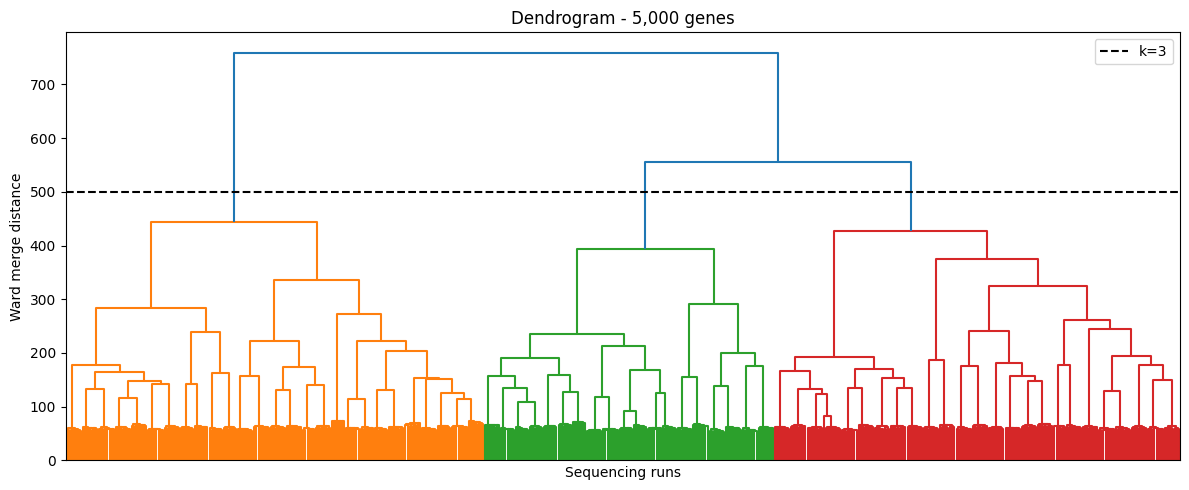

In [5]:
sample_tree = trees[5000]
cut_height = (sample_tree[-plot_k, 2] + sample_tree[-(plot_k - 1), 2]) / 2

plt.figure(figsize=(12, 5))
dendrogram(sample_tree, no_labels=True, color_threshold=cut_height)
plt.axhline(cut_height, color='black', linestyle='--', label=f'k={plot_k}')
plt.xlabel('Sequencing runs')
plt.ylabel('Ward merge distance')
plt.title('Dendrogram - 5,000 genes')
plt.legend()
plt.tight_layout()
plt.savefig(results / 'sample_dendrogram_full.png', dpi=180)
plt.show()
plt.close()

In [16]:
import scipy as sc

cl = cluster_labels
for i in range(len(cl.columns)-1):
    coli = cl.columns[i]
    if "k4" not in coli:
        continue
    for j in range(i+1, len(cl.columns)):
        colj = cl.columns[j]
        if "k4" not in colj:
            continue
        _, p_val, _, _ = sc.stats.chi2_contingency(pd.crosstab(cl[coli], cl[colj]))
        print(coli, colj, p_val)

hierarchical_g10_k4 hierarchical_g100_k4 1.8752571894489033e-31
hierarchical_g10_k4 hierarchical_g1000_k4 4.198193845798433e-56
hierarchical_g10_k4 hierarchical_g5000_k4 2.2826314016494722e-73
hierarchical_g10_k4 hierarchical_g10000_k4 2.9608146017026687e-53
hierarchical_g100_k4 hierarchical_g1000_k4 2.7475296935296966e-171
hierarchical_g100_k4 hierarchical_g5000_k4 7.410391938740638e-141
hierarchical_g100_k4 hierarchical_g10000_k4 9.925221689101102e-147
hierarchical_g1000_k4 hierarchical_g5000_k4 7.274042814391611e-156
hierarchical_g1000_k4 hierarchical_g10000_k4 8.328753658762566e-249
hierarchical_g5000_k4 hierarchical_g10000_k4 5.140160176567107e-184
